<a href="https://colab.research.google.com/github/Hadeel-93/HW-7/blob/main/HW_7_Q2_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader

# Dataset settings
data_path = "/content/data-cifar10/"

transform = transforms.ToTensor()

# Download CIFAR-10
cifar10_train = datasets.CIFAR10(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

cifar10_val = datasets.CIFAR10(
    root=data_path,
    train=False,
    download=True,
    transform=transform
)

print("CIFAR-10 downloaded successfully!")
print("Training images:", len(cifar10_train))
print("Evaluation images:", len(cifar10_val))

100%|██████████| 170M/170M [37:53<00:00, 75.0kB/s]


CIFAR-10 downloaded successfully!
Training images: 50000
Evaluation images: 10000


In [ ]:
BATCH_SIZE = 128

trainloader = DataLoader(
    cifar10_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

valloader = DataLoader(
    cifar10_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(trainloader))
print("Evaluation batches:", len(valloader))

Training batches: 391
Evaluation batches: 79


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import copy
import random

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Experiment settings
NUM_EPOCHS = 100
BATCH_SIZE = 128
LEARNING_RATE = 0.001

print("Number of epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

# Confirm that the DataLoaders are ready
print("Training batches:", len(trainloader))
print("Evaluation batches:", len(valloader))

Using device: cpu
Number of epochs: 100
Batch size: 128
Learning rate: 0.001
Training batches: 391
Evaluation batches: 79


In [ ]:
class CIFAR10_FCNN(nn.Module):

    def __init__(self, hidden1=512, hidden2=256, activation="relu"):
        super(CIFAR10_FCNN, self).__init__()

        if activation == "relu":
            activation_function = nn.ReLU()
        elif activation == "sigmoid":
            activation_function = nn.Sigmoid()
        elif activation == "tanh":
            activation_function = nn.Tanh()
        else:
            raise ValueError("Unsupported activation function")

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * 32 * 32, hidden1),
            activation_function,

            nn.Linear(hidden1, hidden2),
            activation_function,

            nn.Linear(hidden2, 10)
        )

    def forward(self, x):
        return self.network(x)


def count_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def run_experiment(experiment_name, hidden1, hidden2, activation):

    print("\n" + "=" * 65)
    print("Starting:", experiment_name)
    print("=" * 65)

    # Reset seed so initialization is reproducible
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    # Create a fresh model
    model = CIFAR10_FCNN(
        hidden1=hidden1,
        hidden2=hidden2,
        activation=activation
    ).to(device)

    parameters = count_parameters(model)

    # Fresh loss function and optimizer
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "eval_loss": [],
        "eval_accuracy": []
    }

    best_eval_accuracy = 0.0
    best_epoch = 0
    best_model_state = None

    start_time = time.time()

    for epoch in range(NUM_EPOCHS):

        train_loss, train_accuracy = train_one_epoch(
            model, trainloader, criterion, optimizer
        )

        eval_loss, eval_accuracy = evaluate_model(
            model, valloader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["eval_loss"].append(eval_loss)
        history["eval_accuracy"].append(eval_accuracy)

        # Save the best evaluation checkpoint
        if eval_accuracy > best_eval_accuracy:
            best_eval_accuracy = eval_accuracy
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"Epoch [{epoch+1:3d}/{NUM_EPOCHS}] "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_accuracy:.2f}% | "
                f"Eval Loss: {eval_loss:.4f} | "
                f"Eval Acc: {eval_accuracy:.2f}%"
            )

    end_time = time.time()
    training_time = end_time - start_time

    # Final epoch metrics
    final_train_loss = history["train_loss"][-1]
    final_train_accuracy = history["train_accuracy"][-1]
    final_eval_loss = history["eval_loss"][-1]
    final_eval_accuracy = history["eval_accuracy"][-1]

    print("\nExperiment completed:", experiment_name)
    print("Trainable parameters:", f"{parameters:,}")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Final training loss: {final_train_loss:.4f}")
    print(f"Final training accuracy: {final_train_accuracy:.2f}%")
    print(f"Final evaluation accuracy: {final_eval_accuracy:.2f}%")
    print(f"Best evaluation accuracy: {best_eval_accuracy:.2f}%")
    print(f"Best epoch: {best_epoch}")

    return {
        "name": experiment_name,
        "model": model,
        "best_model_state": best_model_state,
        "history": history,
        "parameters": parameters,
        "training_time": training_time,
        "final_train_loss": final_train_loss,
        "final_train_accuracy": final_train_accuracy,
        "final_eval_loss": final_eval_loss,
        "final_eval_accuracy": final_eval_accuracy,
        "best_eval_accuracy": best_eval_accuracy,
        "best_epoch": best_epoch
    }

In [ ]:
def run_experiment(experiment_name, hidden1, hidden2, activation,
                   max_epochs=100, patience=10):

    print("\n" + "=" * 65)
    print("Starting:", experiment_name)
    print("=" * 65)

    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = CIFAR10_FCNN(
        hidden1=hidden1,
        hidden2=hidden2,
        activation=activation
    ).to(device)

    parameters = count_parameters(model)
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "eval_loss": [],
        "eval_accuracy": []
    }

    best_eval_loss = float("inf")
    best_eval_accuracy = 0.0
    best_epoch = 0
    best_model_state = None
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(max_epochs):

        train_loss, train_accuracy = train_one_epoch(
            model, trainloader, criterion, optimizer
        )

        eval_loss, eval_accuracy = evaluate_model(
            model, valloader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["eval_loss"].append(eval_loss)
        history["eval_accuracy"].append(eval_accuracy)

        if eval_loss < best_eval_loss:
            best_eval_loss = eval_loss
            best_eval_accuracy = eval_accuracy
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"Epoch [{epoch+1}/{max_epochs}] "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_accuracy:.2f}% | "
                f"Eval Loss: {eval_loss:.4f} | "
                f"Eval Acc: {eval_accuracy:.2f}%"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    training_time = time.time() - start_time

    # Restore best evaluation-loss checkpoint
    model.load_state_dict(best_model_state)

    # Calculate metrics for the restored best model
    best_train_loss, best_train_accuracy = evaluate_model(
        model, trainloader, criterion
    )

    print("\nCompleted:", experiment_name)
    print("Epochs completed:", len(history["train_loss"]))
    print("Trainable parameters:", f"{parameters:,}")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Best checkpoint epoch: {best_epoch}")
    print(f"Training loss at best checkpoint: {best_train_loss:.4f}")
    print(f"Training accuracy at best checkpoint: {best_train_accuracy:.2f}%")
    print(f"Best evaluation loss: {best_eval_loss:.4f}")
    print(f"Best evaluation accuracy: {best_eval_accuracy:.2f}%")

    return {
        "name": experiment_name,
        "model": model,
        "best_model_state": best_model_state,
        "history": history,
        "parameters": parameters,
        "training_time": training_time,
        "epochs_completed": len(history["train_loss"]),
        "final_train_loss": best_train_loss,
        "final_train_accuracy": best_train_accuracy,
        "final_eval_loss": best_eval_loss,
        "final_eval_accuracy": best_eval_accuracy,
        "best_eval_accuracy": best_eval_accuracy,
        "best_epoch": best_epoch
    }


In [9]:
results_width = run_experiment(
    experiment_name="Increasing Width",
    hidden1=1024,
    hidden2=512,
    activation="relu"
)


Starting: Increasing Width
Epoch [1/100] Train Loss: 1.8493 | Train Acc: 32.64% | Eval Loss: 1.7105 | Eval Acc: 37.90%
Epoch [10/100] Train Loss: 1.3093 | Train Acc: 53.39% | Eval Loss: 1.3940 | Eval Acc: 50.95%
Epoch [20/100] Train Loss: 1.0837 | Train Acc: 61.51% | Eval Loss: 1.3894 | Eval Acc: 52.33%
Early stopping at epoch 27

Completed: Increasing Width
Epochs completed: 27
Trainable parameters: 3,676,682
Training time: 1232.49 seconds
Best checkpoint epoch: 17
Training loss at best checkpoint: 1.0621
Training accuracy at best checkpoint: 62.13%
Best evaluation loss: 1.3515
Best evaluation accuracy: 53.09%


In [10]:
results_sigmoid = run_experiment(
    experiment_name="Sigmoid Activation",
    hidden1=512,
    hidden2=256,
    activation="sigmoid"
)


Starting: Sigmoid Activation
Epoch [1/100] Train Loss: 1.9036 | Train Acc: 30.62% | Eval Loss: 1.7654 | Eval Acc: 35.92%
Epoch [10/100] Train Loss: 1.4032 | Train Acc: 49.64% | Eval Loss: 1.4890 | Eval Acc: 47.11%
Epoch [20/100] Train Loss: 1.2456 | Train Acc: 55.46% | Eval Loss: 1.3882 | Eval Acc: 50.96%
Epoch [30/100] Train Loss: 1.1261 | Train Acc: 59.59% | Eval Loss: 1.4425 | Eval Acc: 49.74%
Early stopping at epoch 30

Completed: Sigmoid Activation
Epochs completed: 30
Trainable parameters: 1,707,274
Training time: 577.37 seconds
Best checkpoint epoch: 20
Training loss at best checkpoint: 1.2031
Training accuracy at best checkpoint: 57.27%
Best evaluation loss: 1.3882
Best evaluation accuracy: 50.96%


In [11]:
results_tanh = run_experiment(
    experiment_name="Tanh Activation",
    hidden1=512,
    hidden2=256,
    activation="tanh"
)


Starting: Tanh Activation
Epoch [1/100] Train Loss: 1.8942 | Train Acc: 31.19% | Eval Loss: 1.7621 | Eval Acc: 36.37%
Epoch [10/100] Train Loss: 1.5578 | Train Acc: 44.16% | Eval Loss: 1.6256 | Eval Acc: 40.65%
Epoch [20/100] Train Loss: 1.4656 | Train Acc: 47.59% | Eval Loss: 1.5418 | Eval Acc: 44.74%
Epoch [30/100] Train Loss: 1.4072 | Train Acc: 49.44% | Eval Loss: 1.5523 | Eval Acc: 45.04%
Early stopping at epoch 38

Completed: Tanh Activation
Epochs completed: 38
Trainable parameters: 1,707,274
Training time: 677.65 seconds
Best checkpoint epoch: 28
Training loss at best checkpoint: 1.3737
Training accuracy at best checkpoint: 50.81%
Best evaluation loss: 1.4964
Best evaluation accuracy: 46.37%


In [12]:
experiment_results = [
    {
        "Experiment": "Q1-a Baseline (ReLU)",
        "Hidden Layers": "512, 256",
        "Activation": "ReLU",
        "Parameters": 1707274,
        "Training Time (sec)": 2619.02,
        "Training Loss": 0.9811,
        "Training Accuracy (%)": 65.71,
        "Evaluation Accuracy (%)": 53.66,
        "Best Epoch": 1
    }
]

for result in [results_width, results_sigmoid, results_tanh]:

    hidden_description = (
        "1024, 512" if result["name"] == "Increasing Width"
        else "512, 256"
    )

    activation = (
        "ReLU" if result["name"] == "Increasing Width"
        else result["name"].replace(" Activation", "")
    )

    experiment_results.append({
        "Experiment": result["name"],
        "Hidden Layers": hidden_description,
        "Activation": activation,
        "Parameters": result["parameters"],
        "Training Time (sec)": round(result["training_time"], 2),
        "Training Loss": round(result["final_train_loss"], 4),
        "Training Accuracy (%)": round(result["final_train_accuracy"], 2),
        "Evaluation Accuracy (%)": round(result["final_eval_accuracy"], 2),
        "Best Epoch": result["best_epoch"]
    })

results_df = pd.DataFrame(experiment_results)

display(results_df)

,Experiment,Hidden Layers,Activation,Parameters,Training Time (sec),Training Loss,Training Accuracy (%),Evaluation Accuracy (%),Best Epoch
0,Q1-a Baseline (ReLU),"512, 256",ReLU,1707274,2619.02,0.9811,65.71,53.66,1
1,Increasing Width,"1024, 512",ReLU,3676682,1232.49,1.0621,62.13,53.09,17
2,Sigmoid Activation,"512, 256",Sigmoid,1707274,577.37,1.2031,57.27,50.96,20
3,Tanh Activation,"512, 256",Tanh,1707274,677.65,1.3737,50.81,46.37,28


In [13]:
baseline_parameters = 1707274
baseline_time = 2619.02
baseline_eval_accuracy = 53.66

comparison_rows = []

for result in [results_width, results_sigmoid, results_tanh]:

    comparison_rows.append({
        "Experiment": result["name"],

        "Parameter Change (%)": round(
            (result["parameters"] - baseline_parameters)
            / baseline_parameters * 100, 2
        ),

        "Training Time Change (%)": round(
            (result["training_time"] - baseline_time)
            / baseline_time * 100, 2
        ),

        "Evaluation Accuracy Change (percentage points)": round(
            result["final_eval_accuracy"] - baseline_eval_accuracy, 2
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

,Experiment,Parameter Change (%),Training Time Change (%),Evaluation Accuracy Change (percentage points)
0,Increasing Width,115.35,-52.94,-0.57
1,Sigmoid Activation,0.00,-77.95,-2.70
2,Tanh Activation,0.00,-74.13,-7.29


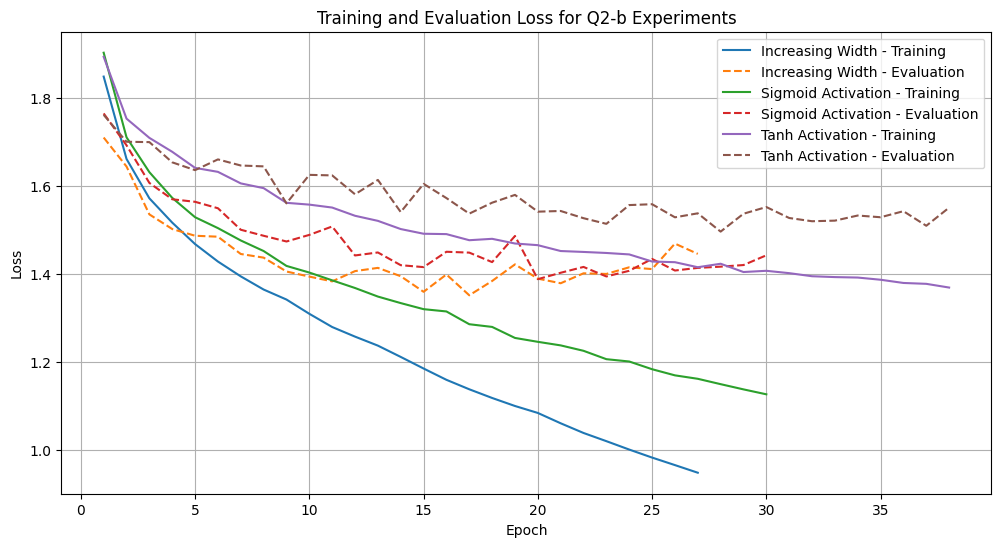

In [15]:
experiments = [
    results_width,
    results_sigmoid,
    results_tanh
]

plt.figure(figsize=(12, 6))

for result in experiments:
    epochs_completed = len(result["history"]["train_loss"])
    epochs_range = range(1, epochs_completed + 1)

    plt.plot(
        epochs_range,
        result["history"]["train_loss"],
        label=result["name"] + " - Training"
    )

    plt.plot(
        epochs_range,
        result["history"]["eval_loss"],
        linestyle="--",
        label=result["name"] + " - Evaluation"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Evaluation Loss for Q2-b Experiments")
plt.legend()
plt.grid(True)
plt.show()

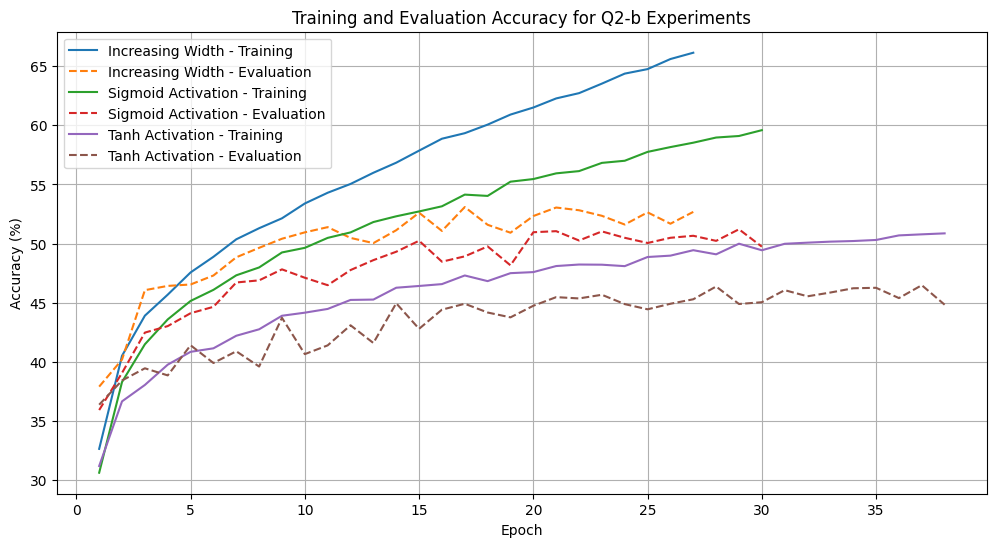

In [17]:
plt.figure(figsize=(12, 6))

for result in experiments:
    epochs_completed = len(result["history"]["train_accuracy"])
    epochs_range = range(1, epochs_completed + 1)

    plt.plot(
        epochs_range,
        result["history"]["train_accuracy"],
        label=result["name"] + " - Training"
    )

    plt.plot(
        epochs_range,
        result["history"]["eval_accuracy"],
        linestyle="--",
        label=result["name"] + " - Evaluation"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Evaluation Accuracy for Q2-b Experiments")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
all_comparisons = [
    {
        "Architecture": "Q1-a Baseline",
        "Hidden Layers": "512, 256",
        "Activation": "ReLU",
        "Evaluation Accuracy (%)": 53.66
    }
]

for result in experiments:
    hidden_layers = (
        "1024, 512" if result["name"] == "Increasing Width"
        else "512, 256"
    )

    activation = (
        "ReLU" if result["name"] == "Increasing Width"
        else result["name"].replace(" Activation", "")
    )

    all_comparisons.append({
        "Architecture": result["name"],
        "Hidden Layers": hidden_layers,
        "Activation": activation,
        "Evaluation Accuracy (%)": result["final_eval_accuracy"]
    })

architecture_df = pd.DataFrame(all_comparisons)

display(
    architecture_df.sort_values(
        by="Evaluation Accuracy (%)",
        ascending=False
    )
)

best_architecture = architecture_df.loc[
    architecture_df["Evaluation Accuracy (%)"].idxmax()
]

print("\nBest architecture based on evaluation accuracy:")
print(best_architecture)

,Architecture,Hidden Layers,Activation,Evaluation Accuracy (%)
0,Q1-a Baseline,"512, 256",ReLU,53.66
1,Increasing Width,"1024, 512",ReLU,53.09
2,Sigmoid Activation,"512, 256",Sigmoid,50.96
3,Tanh Activation,"512, 256",Tanh,46.37



Best architecture based on evaluation accuracy:
Architecture               Q1-a Baseline
Hidden Layers                   512, 256
Activation                          ReLU
Evaluation Accuracy (%)            53.66
Name: 0, dtype: object


In [19]:
best_results = []

for result in experiments:
    best_results.append({
        "Experiment": result["name"],
        "Best Evaluation Accuracy (%)": round(
            result["best_eval_accuracy"], 2
        ),
        "Best Epoch": result["best_epoch"],
        "Final Evaluation Accuracy (%)": round(
            result["final_eval_accuracy"], 2
        )
    })

best_results_df = pd.DataFrame(best_results)

display(best_results_df)

,Experiment,Best Evaluation Accuracy (%),Best Epoch,Final Evaluation Accuracy (%)
0,Increasing Width,53.09,17,53.09
1,Sigmoid Activation,50.96,20,50.96
2,Tanh Activation,46.37,28,46.37


In [20]:
results_df.to_csv("Q2b_Experiment_Results.csv", index=False)

comparison_df.to_csv("Q2b_Comparison_with_Q1a.csv", index=False)

best_results_df.to_csv("Q2b_Best_Evaluation_Results.csv", index=False)

print("All result tables saved successfully!")

All result tables saved successfully!
